In [82]:
import heapq, math, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import fftconvolve
warnings.filterwarnings("ignore")

In [83]:
# Identificación del grupo
C1 = 2028596201
C2 = 2035384971
S = C1 + C2

# Parámetros derivados de S
SEMILLA = S
TAU = 180 + 10 * (S % 9)
EPS = 0.01 * (1 + S % 3)
CONF = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]
ALPHA = 1 - CONF
G_CREC = 1.4 + 0.1 * (S % 7)

T1 = 80 + 10 * (S % 5)
T2 = 400 + 25 * (S % 5)

PI = (4 + S % 6) / 1000
K_MAX = 4 + (S % 5)
R_DESP = S % 6
N_CONS = 10 + (S % 11)

C0 = 2

# Única fuente de aleatoriedad
rng = np.random.default_rng(SEMILLA)

# Estilo de figuras
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

print(f"C1={C1}  C2={C2}  S={S}")
print(f"tau={TAU} ms | eps={EPS} | 1-alpha={CONF} | g={G_CREC:.1f}")
print(f"t1={T1} KB | t2={T2} KB | pi={PI} | k_max={K_MAX} | r={R_DESP} | N={N_CONS}")

C1=2028596201  C2=2035384971  S=4063981172
tau=230 ms | eps=0.03 | 1-alpha=0.99 | g=2.0
t1=100 KB | t2=450 KB | pi=0.006 | k_max=6 | r=2 | N=19


In [84]:
# Los archivos CSV están directamente en la carpeta actual.
RUTA = "solicitudes.csv"
TA_OPT, TB_OPT = 397, 576          # segmento anómalo [397, 576) s hallado en A2 (devianza Poisson)
T_EST = TA_OPT + (1200 - TB_OPT)   # 1021 s de régimen estable

if os.path.exists(RUTA):
    MODO_DATOS = True
    df = pd.read_csv(RUTA).drop_duplicates(keep="first").copy()                  # A1.1 duplicados
    df.loc[df.tam_kb > 5000, "tam_kb"] /= 1024.0                                 # A1.2 bytes -> KB
    df.loc[(df.cache_hit == 1) & df.gpu_ms.isna(), "gpu_ms"] = 0.0               # A1.3 caché => G = 0
    m = (df.cache_hit == 1) & df.red_ms.isna()
    df.loc[m, "red_ms"] = df.loc[m, "latencia_ms"]                               #      caché => L = red
    df = df.dropna(subset=["red_ms", "gpu_ms"])
    df = df[df.latencia_ms > 0]                                                  # A1.4 centinela -1
    df = df[~(df.latencia_ms + 0.02 < df.red_ms + df.gpu_ms)].copy()             # A1.5 L < red + G
    est_mask = (df.t_llegada_s < TA_OPT) | (df.t_llegada_s >= TB_OPT)
    df_est, df_pico = df[est_mask].copy(), df[~est_mask].copy()
    print(f"Datos reales: {len(df)} filas limpias | régimen estable: {len(df_est)} | segmento anómalo: {len(df_pico)}")
else:
    MODO_DATOS = False
    print("No se encontró solicitudes.csv -> se usan los parámetros ya ajustados en las Partes A-F (modo respaldo).")

Datos reales: 32174 filas limpias | régimen estable: 22040 | segmento anómalo: 10134


In [85]:
# Los archivos CSV están directamente en la carpeta actual.
RUTA = ""

sol_raw = pd.read_csv(RUTA + "solicitudes.csv")
mon_raw = pd.read_csv(RUTA + "monitoreo.csv")

# Copias de trabajo: los *_raw nunca se modifican
sol = sol_raw.copy()
mon = mon_raw.copy()

print("solicitudes:", sol_raw.shape)
print(sol_raw.dtypes, "\n")
print(sol_raw.head(), "\n")

print("monitoreo:", mon_raw.shape)
print(mon_raw.head())

solicitudes: (32472, 10)
id_solicitud      int64
t_llegada_s     float64
tam_kb          float64
cache_hit         int64
version          object
red_ms          float64
gpu_ms          float64
latencia_ms     float64
intentos          int64
exito             int64
dtype: object 

   id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  \
0             1       0.0060  108.47          0       B   25.29    8.37   
1             2       0.1270  629.91          0       A   27.24  149.39   
2             3       0.1612  179.72          0       B   24.69   49.68   
3             4       0.1690  429.34          0       B   21.15   66.91   
4             5       0.1867  229.65          0       B   33.99   33.09   

   latencia_ms  intentos  exito  
0        33.65         1      1  
1       176.63         1      1  
2        74.37         1      1  
3       129.94         2      1  
4       156.75         1      1   

monitoreo: (6000, 4)
   minuto  D1  D2  incidente
0       1   

In [86]:
#PARÁMETROS DEL MODELO (régimen estable)
if MODO_DATOS:
    nc = df_est[df_est.cache_hit == 0]
    log_g = np.log(nc.gpu_ms.values[nc.gpu_ms.values > 0])
    k_int = df_est.intentos.values
    resid = nc.latencia_ms.values - nc.red_ms.values - nc.gpu_ms.values        # espera + penalización por reintento
    pen_est = max(np.polyfit(nc.intentos.values - 1, resid, 1)[0], 0.0)        # ms extra por intento adicional
    est = dict(n_est=len(df_est), T_est=T_EST, lam=len(df_est) / T_EST,
               k_cache=int((df_est.cache_hit == 1).sum()), p_cache=(df_est.cache_hit == 1).mean(),
               n_nc=len(log_g), mu_ln=log_g.mean(), sig_ln=log_g.std(ddof=0),     # MLE lognormal (forma cerrada)
               n_red=len(df_est), red_mu=df_est.red_ms.mean(), red_sd=df_est.red_ms.std(ddof=1),
               p_int=tuple(np.bincount(k_int, minlength=4)[1:4] / len(k_int)), pen=pen_est,
               lam_pico=len(df_pico) / (TB_OPT - TA_OPT))
    REAL = dict(media=df_est.latencia_ms.mean(), sd=df_est.latencia_ms.std(ddof=1),
                p_viol=(df_est.latencia_ms > TAU).mean(), n=len(df_est),
                cuantiles={q: df_est.latencia_ms.quantile(q) for q in [0.5, 0.9, 0.95, 0.99, 0.999]})
else:
    # Valores tomados de las salidas de los cuadernos A/B, C y F (régimen estable). G se ajustó por
    # momentos: media 50.30 ms y DE ~42.2 ms de las solicitudes no cacheadas (Parte F, tabla de validación).
    sg2 = math.log(1 + (42.2 / 50.30) ** 2)
    est = dict(n_est=22040, T_est=T_EST, lam=21.5867, k_cache=int(round(0.3509 * 22040)), p_cache=0.3509,
               n_nc=14307, mu_ln=math.log(50.30) - sg2 / 2, sig_ln=math.sqrt(sg2),
               n_red=22040, red_mu=26.42, red_sd=3.90, p_int=(0.8245, 0.1459, 0.0296), pen=0.0,
               lam_pico=10134 / (TB_OPT - TA_OPT))
    REAL = dict(media=63.19, sd=46.00, p_viol=0.0100, n=22009, cuantiles={0.5: 50.09})

THETA0 = {k: est[k] for k in ["lam", "p_cache", "mu_ln", "sig_ln", "red_mu", "red_sd", "p_int", "pen"]}
EG = math.exp(THETA0["mu_ln"] + THETA0["sig_ln"] ** 2 / 2)             # E[G | no caché] en ms
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in THETA0.items()})
print(f"E[G | no caché] = {EG:.2f} ms | carga ofrecida a las GPUs (g=1): a = {est["lam"]*(1-est["p_cache"])*EG/1000:.3f} Erlangs")

{'lam': 21.5867, 'p_cache': np.float64(0.3509), 'mu_ln': np.float64(3.6232), 'sig_ln': np.float64(0.7904), 'red_mu': np.float64(26.4248), 'red_sd': 3.8866, 'p_int': (np.float64(0.824546279491833), np.float64(0.14591651542649728), np.float64(0.029537205081669692)), 'pen': 0.0}
E[G | no caché] = 51.19 ms | carga ofrecida a las GPUs (g=1): a = 0.717 Erlangs


In [87]:
#SIMULADOR DE MONTECARLO (hecho por nosotros)
def simular_pool(gen, lam, p_cache, mu_ln, sig_ln, red_mu, red_sd, c, T, calentamiento=30.0,
                 pen=0.0, p_int=(1.0, 0.0, 0.0), g_emp=None):
    # Simula T segundos del sistema con c GPUs y cola única FIFO. Devuelve (L, espera, es_cache) tras el calentamiento.
    n = gen.poisson(lam * T)                               # nº de llegadas ~ Poisson(lam*T)
    t = np.sort(gen.uniform(0.0, T, n))                    # dado n, los instantes son uniformes ordenados
    es_cache = gen.random(n) < p_cache                     # cache hit ~ Bernoulli(p)
    red = np.maximum(gen.normal(red_mu, red_sd, n), 1.0)   # red ~ Normal (truncada en 1 ms)
    g_nc = gen.lognormal(mu_ln, sig_ln, n) if g_emp is None else gen.choice(g_emp, size=n)   # lognormal (o remuestreo empírico)
    G = np.where(es_cache, 0.0, g_nc)                      # G = 0 si caché
    espera = np.zeros(n)
    idx = np.flatnonzero(~es_cache)                        # solo estas solicitudes usan GPU y hacen cola
    libres = [0.0] * c                                     # instante (s) en que cada GPU queda libre
    heapq.heapify(libres)
    w = np.empty(idx.size)
    for j, (llegada, servicio) in enumerate(zip(t[idx].tolist(), (G[idx] / 1000.0).tolist())):
        libre = libres[0]                                  # primera GPU que se libera (política FIFO)
        inicio = llegada if llegada > libre else libre
        w[j] = inicio - llegada
        heapq.heapreplace(libres, inicio + servicio)       # esa GPU queda ocupada hasta fin de servicio
    espera[idx] = w * 1000.0
    k = gen.choice([1, 2, 3], p=p_int, size=n)             # nº de intentos del SDK
    L = red + espera + G + pen * (k - 1)                   # latencia extremo a extremo
    ok = t >= calentamiento
    return L[ok], espera[ok], es_cache[ok]

def replicas(theta, g, c, R, T, calentamiento, tau, gen):
    # R réplicas independientes (cada una con su propia semilla derivada del generador único).
    semillas = gen.integers(0, 2**63 - 1, size=R)
    prop, esp, Ls = [], [], []
    for s in semillas:
        L, w, _ = simular_pool(np.random.default_rng(int(s)), g * theta["lam"], theta["p_cache"], theta["mu_ln"],
                               theta["sig_ln"], theta["red_mu"], theta["red_sd"], c, T, calentamiento,
                               theta["pen"], theta["p_int"], theta.get("g_emp"))
        prop.append(np.mean(L > tau)); esp.append(w.mean()); Ls.append(L)
    return np.array(prop), np.array(esp), Ls

def ic_t(x, conf=CONF):
    m, R = x.mean(), len(x)
    h = stats.t.ppf(1 - (1 - conf) / 2, R - 1) * x.std(ddof=1) / math.sqrt(R)
    return m, m - h, m + h

def wilson(k, n, conf=CONF):
    r = stats.binomtest(int(k), int(n)).proportion_ci(conf, method="wilson")
    return r.low, r.high

In [88]:
#MODELO ANALÍTICO SIMPLIFICADO (para G2 y G3)
# M/G/c aproximado: espera de Erlang-C + corrección de Allen-Cunneen, convolucionada con red y G (rejilla numérica).
def erlang_c(c, a):
    # Probabilidad de que una solicitud que va a GPU tenga que esperar (a = lam*E[S] en Erlangs, a < c).
    num = a**c / (math.factorial(c) * (1 - a / c))
    den = sum(a**k / math.factorial(k) for k in range(c)) + num
    return num / den

def p_viol_analitico(theta, g, c, tau, dx=0.1, Lmax=700.0):
    lam_gpu = g * theta["lam"] * (1 - theta["p_cache"])                  # tasa hacia las GPUs (1/s)
    ES = math.exp(theta["mu_ln"] + theta["sig_ln"]**2 / 2) / 1000.0      # E[G] en segundos
    a = lam_gpu * ES
    if a >= c:
        return 1.0                                                       # carga >= capacidad: inestable
    cv2 = math.exp(theta["sig_ln"]**2) - 1                               # CV^2 de G lognormal
    Pw = erlang_c(c, a)
    tasa_espera = (c / ES - lam_gpu) * 2.0 / (1.0 + cv2) / 1000.0        # 1/ms, cola exponencial (Allen-Cunneen)
    x = np.arange(0.0, Lmax + dx, dx)
    pmf = lambda cdf: np.diff(cdf(x))
    p_red = pmf(lambda z: stats.norm.cdf(z, theta["red_mu"], theta["red_sd"]))
    p_G   = pmf(lambda z: stats.lognorm.cdf(z, theta["sig_ln"], scale=math.exp(theta["mu_ln"])))
    p_W   = pmf(lambda z: 1 - Pw * np.exp(-tasa_espera * z))            # mezcla: átomo en 0 + exponencial
    p_W[0] += 1 - Pw                                                    # átomo en 0: no espera
    S = fftconvolve(fftconvolve(p_red, p_G)[:len(x)], p_W)[:len(x)]      # red + G + espera
    cdfS = np.cumsum(S)
    total = 0.0
    for k, pk in zip([1, 2, 3], theta["p_int"]):
        desp = theta["pen"] * (k - 1)
        i = int((tau - desp) / dx)
        sin_cache = 1.0 - (cdfS[i - 1] if i > 0 else 0.0)
        con_cache = 1.0 - stats.norm.cdf(tau - desp, theta["red_mu"], theta["red_sd"])
        total += pk * ((1 - theta["p_cache"]) * sin_cache + theta["p_cache"] * con_cache)
    return total

**G1.**

In [89]:
#1. CÓDIGO
R_VAL, T_VAL, WARM_VAL = 40, 1000.0, 60.0           # 40 réplicas de 1000 s (60 s de calentamiento descartados)
variantes = {"sin reintentos": dict(THETA0, pen=0.0)}
if THETA0["pen"] > 0: variantes["con reintentos"] = THETA0

qs = [0.5, 0.9, 0.95, 0.99, 0.999]
resultados_g1 = {}
for nombre, th in variantes.items():
    prop, esp, Ls = replicas(th, 1.0, C0, R_VAL, T_VAL, WARM_VAL, TAU, rng)
    Lall = np.concatenate(Ls)
    cuant = np.array([[np.quantile(L, q) for q in qs] for L in Ls])          # cuantiles por réplica
    resultados_g1[nombre] = dict(prop=ic_t(prop), media=Lall.mean(), sd=Lall.std(ddof=1), Lall=Lall,
                                 cuant=[ic_t(cuant[:, i]) for i in range(len(qs))], espera=esp.mean())

# Latencia real: IC Wilson para P(L>tau) y bootstrap para cuantiles (solo si hay datos reales)
if MODO_DATOS:
    lat = df_est.latencia_ms.values
    k_real = int((lat > TAU).sum()); ic_real = wilson(k_real, len(lat))
    boot = np.quantile(rng.choice(lat, size=(500, len(lat))), qs, axis=1)
    cuant_real = [(np.quantile(lat, q), *np.percentile(boot[i], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]))
                  for i, q in enumerate(qs)]
else:
    ic_real = wilson(round(REAL["p_viol"] * REAL["n"]), REAL["n"])

In [90]:
#2. RESULTADOS
filas = []
for nombre, r in resultados_g1.items():
    fila = {"Modelo": f"Simulación ({nombre})", "Media (ms)": r["media"], "DE (ms)": r["sd"],
            "P(L>tau) [%]": 100 * r["prop"][0], f"IC{CONF:.0%} inf [%]": 100 * r["prop"][1], f"IC{CONF:.0%} sup [%]": 100 * r["prop"][2],
            "Espera media (ms)": r["espera"]}
    for q, (m, lo, hi) in zip(qs, r["cuant"]): fila[f"q{q*100:g}%"] = m
    filas.append(fila)
fila_real = {"Modelo": "DATOS REALES (estable)", "Media (ms)": REAL["media"], "DE (ms)": REAL["sd"],
             "P(L>tau) [%]": 100 * REAL["p_viol"], f"IC{CONF:.0%} inf [%]": 100 * ic_real[0], f"IC{CONF:.0%} sup [%]": 100 * ic_real[1]}
for q in qs:
    if q in REAL["cuantiles"]: fila_real[f"q{q*100:g}%"] = REAL["cuantiles"][q]
filas.append(fila_real)
tabla_g1 = pd.DataFrame(filas).set_index("Modelo")
display(tabla_g1.round(3).T)

dentro = ic_real[0] <= resultados_g1["sin reintentos"]["prop"][0] <= ic_real[1]
print(f"\nP(L>tau) simulada (sin reintentos) dentro del IC real {CONF:.0%}: {dentro}")
if MODO_DATOS:
    print("\nCuantiles: real [IC bootstrap] vs simulado [IC entre réplicas]")
    for q, cr, cs in zip(qs, cuant_real, resultados_g1["sin reintentos"]["cuant"]):
        print(f"  q{q*100:g}%: real {cr[0]:.1f} [{cr[1]:.1f}, {cr[2]:.1f}]  |  sim {cs[0]:.1f} [{cs[1]:.1f}, {cs[2]:.1f}]")
    print("KS 2 muestras (real vs sim):", stats.ks_2samp(lat, resultados_g1["sin reintentos"]["Lall"][::50]))

Modelo,Simulación (sin reintentos),DATOS REALES (estable)
Media (ms),64.118,63.320
DE (ms),50.778,46.416
P(L>tau) [%],1.429,1.034
IC99% inf [%],1.388,0.873
IC99% sup [%],1.470,1.225
Espera media (ms),4.436,NaN
q50%,49.697,50.105
q90%,123.608,121.830
q95%,158.881,152.705
q99%,252.675,231.226



P(L>tau) simulada (sin reintentos) dentro del IC real 99%: False

Cuantiles: real [IC bootstrap] vs simulado [IC entre réplicas]
  q50%: real 50.1 [49.3, 51.0]  |  sim 49.7 [49.5, 49.9]
  q90%: real 121.8 [119.9, 123.6]  |  sim 123.6 [123.0, 124.2]
  q95%: real 152.7 [149.2, 156.5]  |  sim 158.9 [157.9, 159.9]
  q99%: real 231.2 [221.0, 239.3]  |  sim 252.7 [249.9, 255.4]
  q99.9%: real 366.5 [330.4, 400.5]  |  sim 432.1 [423.0, 441.2]
KS 2 muestras (real vs sim): KstestResult(statistic=np.float64(0.008207464945161447), pvalue=np.float64(0.5516027130617422), statistic_location=np.float64(59.10752003527241), statistic_sign=np.int8(-1))


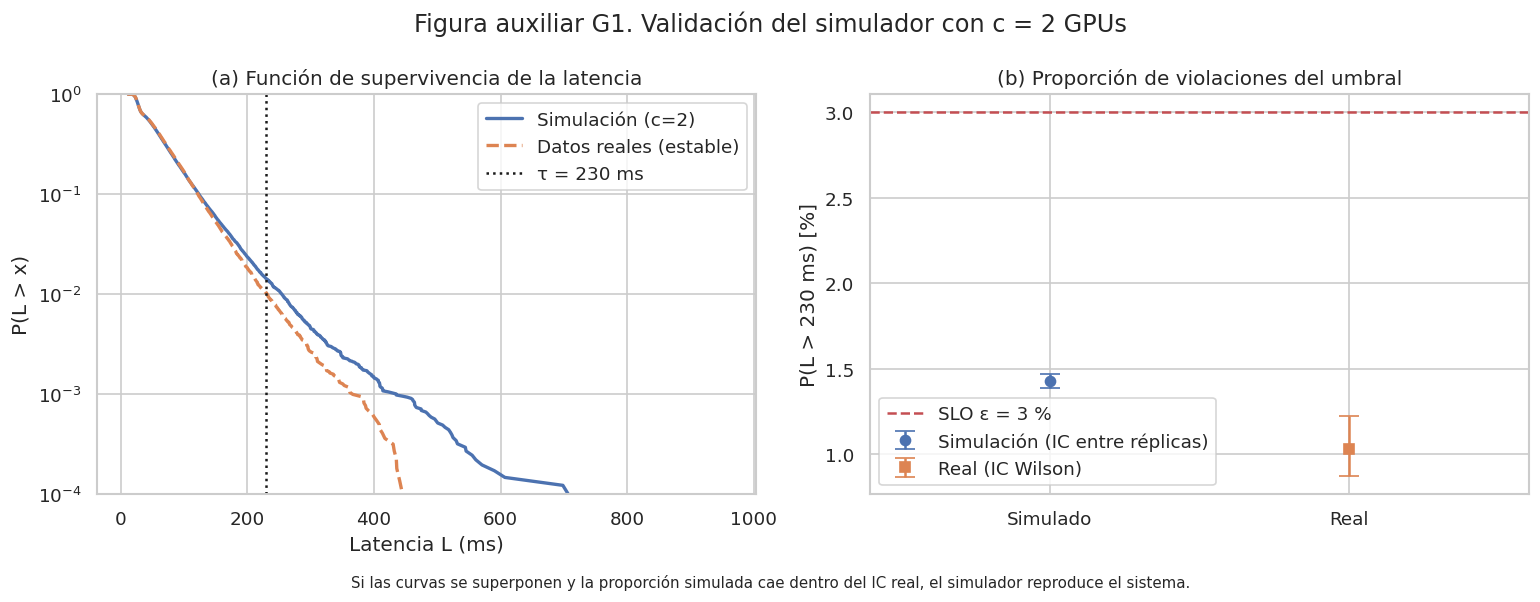

In [91]:
#3. GRÁFICA
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
Lsim = resultados_g1["sin reintentos"]["Lall"]
xs = np.sort(Lsim[::20]); ax[0].plot(xs, 1 - np.arange(1, len(xs) + 1) / len(xs), label="Simulación (c=2)", lw=2)
if MODO_DATOS:
    xr = np.sort(lat); ax[0].plot(xr, 1 - np.arange(1, len(xr) + 1) / len(xr), "--", label="Datos reales (estable)", lw=2)
ax[0].axvline(TAU, color="k", ls=":", label=f"τ = {TAU} ms"); ax[0].set_yscale("log"); ax[0].set_ylim(1e-4, 1)
ax[0].set(title="(a) Función de supervivencia de la latencia", xlabel="Latencia L (ms)", ylabel="P(L > x)"); ax[0].legend()
m, lo, hi = resultados_g1["sin reintentos"]["prop"]
ax[1].errorbar([0], [100 * m], yerr=[[100 * (m - lo)], [100 * (hi - m)]], fmt="o", capsize=6, label="Simulación (IC entre réplicas)")
ax[1].errorbar([1], [100 * REAL["p_viol"]], yerr=[[100 * (REAL["p_viol"] - ic_real[0])], [100 * (ic_real[1] - REAL["p_viol"])]],
               fmt="s", capsize=6, label="Real (IC Wilson)")
ax[1].axhline(100 * EPS, color="r", ls="--", label=f"SLO ε = {100*EPS:.0f} %")
ax[1].set_xticks([0, 1], ["Simulado", "Real"]); ax[1].set_xlim(-0.6, 1.6)
ax[1].set(title="(b) Proporción de violaciones del umbral", ylabel=f"P(L > {TAU} ms) [%]"); ax[1].legend()
fig.suptitle("Figura auxiliar G1. Validación del simulador con c = 2 GPUs")
fig.text(0.5, -0.02, "Si las curvas se superponen y la proporción simulada cae dentro del IC real, el simulador reproduce el sistema.", ha="center", fontsize=9)
fig.tight_layout(); fig.savefig("figura_G1_validacion.png", dpi=200, bbox_inches="tight"); plt.show()

**G2.**

In [92]:
#1. CÓDIGO
T_REP, WARM_REP, H_OBJ = 900.0, 60.0, 0.0015        # horizonte por réplica, calentamiento y semiancho objetivo
a_carga = G_CREC * THETA0["lam"] * (1 - THETA0["p_cache"]) * EG / 1000.0       # Erlangs ofrecidos
c_min_estable = int(math.floor(a_carga)) + 1                                   # menor c con rho < 1
print(f"Carga ofrecida a = {a_carga:.3f} Erlangs  ->  mínimo c para estabilidad: {c_min_estable}")

filas = []
for c in range(1, 6):
    rho = a_carga / c
    if rho >= 1:                                       # inestable: no hay régimen estacionario
        prop, esp, _ = replicas(THETA0, G_CREC, c, 10, 300.0, 0.0, TAU, rng)
        m, lo, hi = ic_t(prop); R_c = 10
    else:
        piloto, _, _ = replicas(THETA0, G_CREC, c, 10, T_REP, WARM_REP, TAU, rng)
        tcrit = stats.t.ppf(1 - ALPHA / 2, 9)
        R_c = int(np.clip(math.ceil((tcrit * piloto.std(ddof=1) / H_OBJ) ** 2), 10, 200))
        prop, esp, _ = replicas(THETA0, G_CREC, c, R_c, T_REP, WARM_REP, TAU, rng)
        m, lo, hi = ic_t(prop)
    filas.append(dict(c=c, rho=rho, R=R_c, P_viol=m, IC_inf=lo, IC_sup=hi, espera_media_ms=esp.mean(),
                      P_analitico=p_viol_analitico(THETA0, G_CREC, c, TAU),
                      cumple_SLO=(m <= EPS), cumple_robusto=(hi <= EPS), estable=(rho < 1)))
tabla_g2 = pd.DataFrame(filas)
c_estrella = int(tabla_g2.loc[(tabla_g2.cumple_SLO) & (tabla_g2.estable), "c"].min())
c_robusto  = tabla_g2.loc[(tabla_g2.cumple_robusto) & (tabla_g2.estable), "c"]
c_robusto  = int(c_robusto.min()) if len(c_robusto) else None

# Prueba de estrés (extra): tasa observada en el segmento anómalo de A2 (no es el escenario g, pero sí ocurrió)
filas_pico = []
for c in range(2, 9):
    prop, _, _ = replicas(THETA0, est["lam_pico"] / THETA0["lam"], c, 10, 600.0, 60.0, TAU, rng)
    filas_pico.append((c, *ic_t(prop)))
    if filas_pico[-1][1] <= EPS: break

Carga ofrecida a = 1.435 Erlangs  ->  mínimo c para estabilidad: 2


In [93]:
#2. RESULTADOS
fmt = tabla_g2.copy()
for col in ["P_viol", "IC_inf", "IC_sup", "P_analitico"]: fmt[col] = (100 * fmt[col]).round(2)
fmt["rho"] = fmt["rho"].round(3); fmt["espera_media_ms"] = fmt["espera_media_ms"].round(2)
print(f"IC al {CONF:.0%} (t de Student sobre R réplicas independientes); P en %, SLO: P(L>{TAU}) <= {100*EPS:.0f} %")
display(fmt)
print(f"\nMenor c que cumple el SLO (estimación puntual): c* = {c_estrella}")
print(f"Menor c que cumple con el LÍMITE SUPERIOR del IC <= eps: {c_robusto}")
print(f"\nEstrés con la tasa del segmento anómalo ({est['lam_pico']:.1f} sol/s, x{est['lam_pico']/THETA0['lam']:.2f} la normal):")
for c, m, lo, hi in filas_pico: print(f"  c={c}: P(L>tau) = {100*m:.2f} % [{100*lo:.2f}, {100*hi:.2f}]")

IC al 99% (t de Student sobre R réplicas independientes); P en %, SLO: P(L>230) <= 3 %


,c,rho,R,P_viol,IC_inf,IC_sup,espera_media_ms,P_analitico,cumple_SLO,cumple_robusto,estable
0,1,1.435,10,64.76,64.26,65.26,43311.59,100.00,False,False,False
1,2,0.717,200,7.73,7.60,7.86,32.64,7.81,False,False,True
2,3,0.478,10,1.31,1.20,1.42,4.01,1.32,True,True,True
3,4,0.359,10,1.09,1.03,1.14,0.71,1.08,True,True,True
4,5,0.287,10,1.05,1.00,1.10,0.14,1.05,True,True,True



Menor c que cumple el SLO (estimación puntual): c* = 3
Menor c que cumple con el LÍMITE SUPERIOR del IC <= eps: 3

Estrés con la tasa del segmento anómalo (56.6 sol/s, x2.62 la normal):
  c=2: P(L>tau) = 38.78 % [35.10, 42.47]
  c=3: P(L>tau) = 2.19 % [1.97, 2.41]


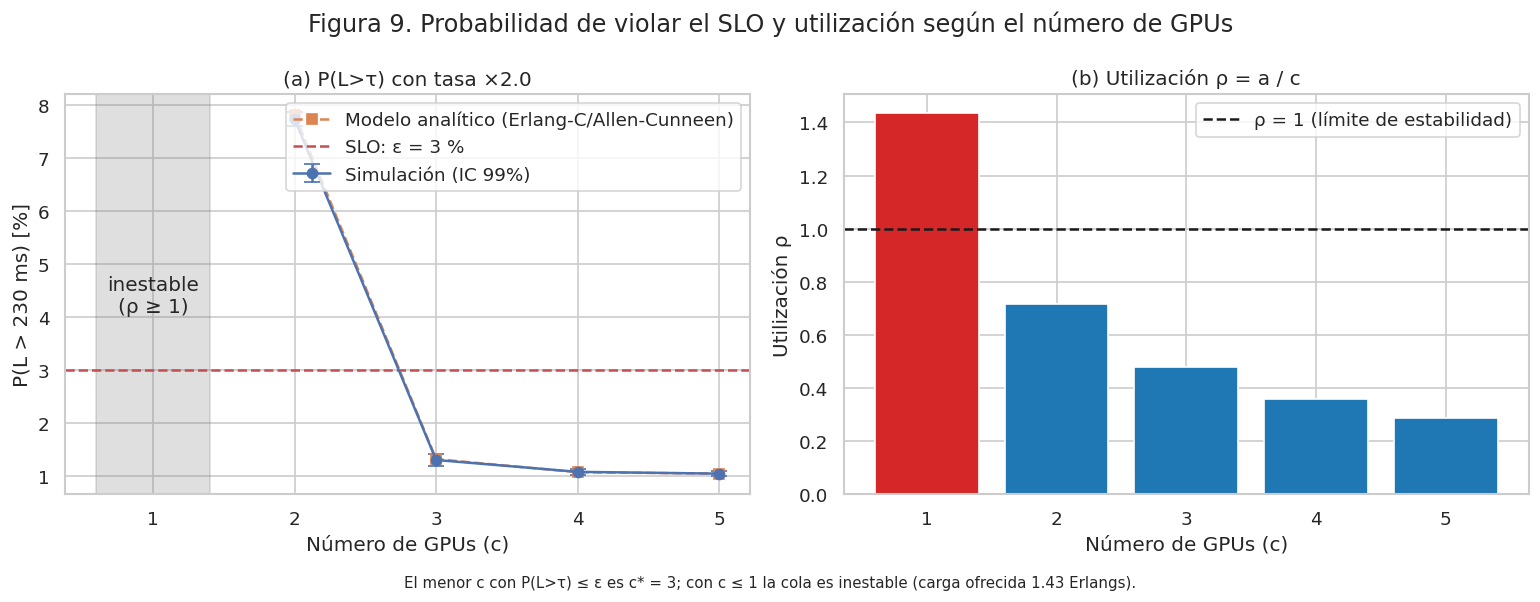

In [94]:
#3. GRÁFICA: FIGURA 9
est_ok = tabla_g2[tabla_g2.estable]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].errorbar(est_ok.c, 100 * est_ok.P_viol, yerr=[100 * (est_ok.P_viol - est_ok.IC_inf), 100 * (est_ok.IC_sup - est_ok.P_viol)],
               fmt="o-", capsize=5, label=f"Simulación (IC {CONF:.0%})")
ax[0].plot(est_ok.c, 100 * est_ok.P_analitico, "s--", label="Modelo analítico (Erlang-C/Allen-Cunneen)")
ax[0].axhline(100 * EPS, color="r", ls="--", label=f"SLO: ε = {100*EPS:.0f} %")
for c in tabla_g2[~tabla_g2.estable].c: ax[0].axvspan(c - 0.4, c + 0.4, color="gray", alpha=0.25)
ax[0].text(1, 0.5 * ax[0].get_ylim()[1], "inestable\n(ρ ≥ 1)", ha="center")
ax[0].set_xticks(tabla_g2.c); ax[0].set(title=f"(a) P(L>τ) con tasa ×{G_CREC:.1f}", xlabel="Número de GPUs (c)", ylabel=f"P(L > {TAU} ms) [%]"); ax[0].legend(loc="upper right")
ax[1].bar(tabla_g2.c, tabla_g2.rho, color=np.where(tabla_g2.rho >= 1, "tab:red", "tab:blue"))
ax[1].axhline(1, color="k", ls="--", label="ρ = 1 (límite de estabilidad)")
ax[1].set_xticks(tabla_g2.c); ax[1].set(title="(b) Utilización ρ = a / c", xlabel="Número de GPUs (c)", ylabel="Utilización ρ"); ax[1].legend()
fig.suptitle("Figura 9. Probabilidad de violar el SLO y utilización según el número de GPUs")
fig.text(0.5, -0.02, f"El menor c con P(L>τ) ≤ ε es c* = {c_estrella}; con c ≤ {c_min_estable-1} la cola es inestable (carga ofrecida {a_carga:.2f} Erlangs).", ha="center", fontsize=9)
fig.tight_layout(); fig.savefig("figura9_capacidad.png", dpi=200, bbox_inches="tight"); plt.show()

**G3.**

In [95]:
#1. CÓDIGO
def extraer_theta(gen, est, base):
    th = dict(base)
    th["lam"] = gen.gamma(est["n_est"], 1.0 / est["T_est"])
    th["p_cache"] = gen.beta(est["k_cache"] + 1, est["n_est"] - est["k_cache"] + 1)
    th["sig_ln"] = math.sqrt(est["n_nc"] * est["sig_ln"] ** 2 / gen.chisquare(est["n_nc"] - 1))
    th["mu_ln"] = gen.normal(est["mu_ln"], th["sig_ln"] / math.sqrt(est["n_nc"]))
    th["red_mu"] = gen.normal(est["red_mu"], est["red_sd"] / math.sqrt(est["n_red"]))
    return th

def c_estrella_sim(th, gen, R=6, T=400.0, warm=40.0, c_max=8):
    a = G_CREC * th["lam"] * (1 - th["p_cache"]) * math.exp(th["mu_ln"] + th["sig_ln"]**2 / 2) / 1000.0
    for c in range(max(1, int(math.floor(a)) + 1), c_max + 1):      # c < floor(a)+1 es inestable: se omite
        if replicas(th, G_CREC, c, R, T, warm, TAU, gen)[0].mean() <= EPS: return c
    return c_max + 1

def c_estrella_analitico(th, c_max=8):
    for c in range(1, c_max + 1):
        if p_viol_analitico(th, G_CREC, c, TAU) <= EPS: return c
    return c_max + 1

B_G3 = 300
c_sim, c_ana, a_draws = [], [], []
for _ in range(B_G3):
    th = extraer_theta(rng, est, THETA0)
    c_sim.append(c_estrella_sim(th, rng)); c_ana.append(c_estrella_analitico(th))
    a_draws.append(G_CREC * th["lam"] * (1 - th["p_cache"]) * math.exp(th["mu_ln"] + th["sig_ln"]**2 / 2) / 1000.0)
c_sim, c_ana, a_draws = np.array(c_sim), np.array(c_ana), np.array(a_draws)

In [96]:
#2. RESULTADOS
vals = np.arange(1, 9)
dist = pd.DataFrame({"c*": vals, "Simulación [%]": [100 * np.mean(c_sim == v) for v in vals],
                     "Analítico [%]": [100 * np.mean(c_ana == v) for v in vals]})
display(dist[(dist["Simulación [%]"] > 0) | (dist["Analítico [%]"] > 0)].round(1))
acum = lambda x, v: np.mean(x <= v)
c_rob_sim = int(min(v for v in vals if acum(c_sim, v) >= 0.95))
c_rob_ana = int(min(v for v in vals if acum(c_ana, v) >= 0.95))
print(f"Moda de c* (simulación): {int(stats.mode(c_sim, keepdims=False).mode)} | (analítico): {int(stats.mode(c_ana, keepdims=False).mode)}")
print(f"c tal que P(c* <= c) >= 95 %: simulación = {c_rob_sim} | analítico = {c_rob_ana}")
print(f"Carga ofrecida a (Erlangs): media {a_draws.mean():.3f}, IC95% [{np.percentile(a_draws,2.5):.3f}, {np.percentile(a_draws,97.5):.3f}]")
print(f"Concordancia entre c* simulado y analítico: {100*np.mean(c_sim == c_ana):.1f} % de las iteraciones")

,c*,Simulación [%],Analítico [%]
2,3,100.0,100.0


Moda de c* (simulación): 3 | (analítico): 3
c tal que P(c* <= c) >= 95 %: simulación = 3 | analítico = 3
Carga ofrecida a (Erlangs): media 1.434, IC95% [1.405, 1.462]
Concordancia entre c* simulado y analítico: 100.0 % de las iteraciones


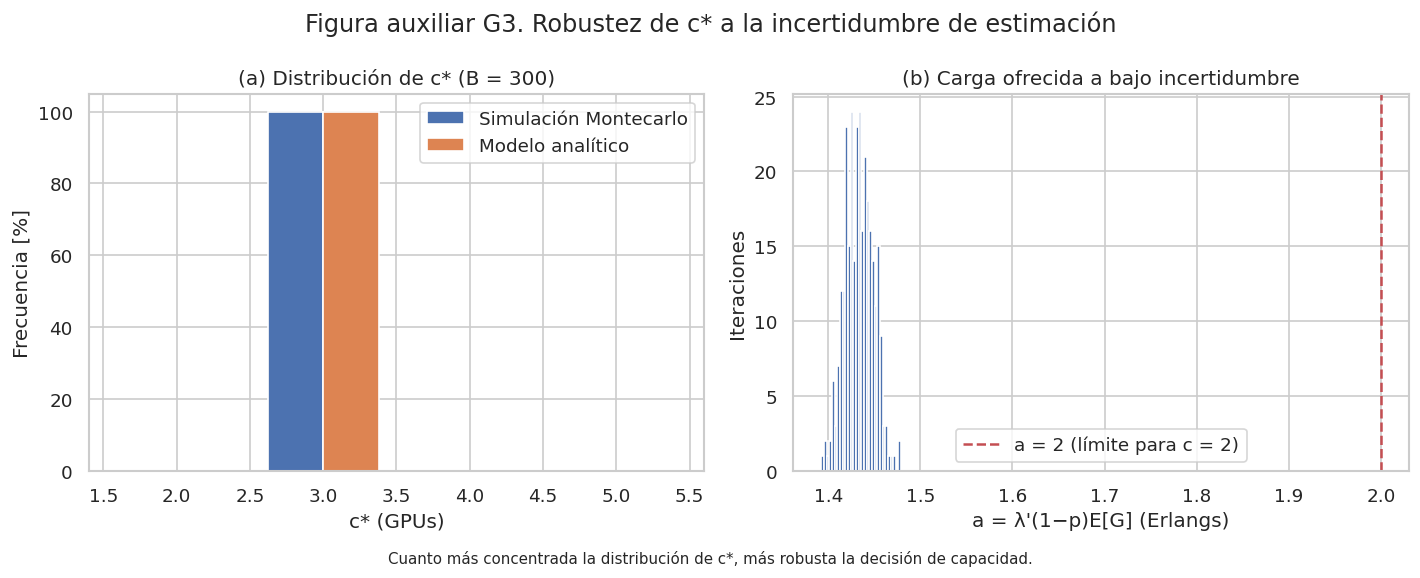

In [97]:
#3. GRÁFICA
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
w = 0.38
ax[0].bar(vals - w / 2, 100 * np.array([np.mean(c_sim == v) for v in vals]), w, label="Simulación Montecarlo")
ax[0].bar(vals + w / 2, 100 * np.array([np.mean(c_ana == v) for v in vals]), w, label="Modelo analítico")
ax[0].set_xlim(1.4, 5.6); ax[0].set(title=f"(a) Distribución de c* (B = {B_G3})", xlabel="c* (GPUs)", ylabel="Frecuencia [%]"); ax[0].legend()
ax[1].hist(a_draws, bins=30); ax[1].axvline(2, color="r", ls="--", label="a = 2 (límite para c = 2)")
ax[1].set(title="(b) Carga ofrecida a bajo incertidumbre", xlabel="a = λ'(1−p)E[G] (Erlangs)", ylabel="Iteraciones"); ax[1].legend()
fig.suptitle("Figura auxiliar G3. Robustez de c* a la incertidumbre de estimación")
fig.text(0.5, -0.02, "Cuanto más concentrada la distribución de c*, más robusta la decisión de capacidad.", ha="center", fontsize=9)
fig.tight_layout(); fig.savefig("figura_G3_robustez.png", dpi=200, bbox_inches="tight"); plt.show()

In [98]:
# G3 (extra) — SENSIBILIDAD A LA FORMA DE G
# C2 mostró que la lognormal no es perfecta (KS rechaza). ¿Cambia c* si G se remuestrea de los datos reales?
variantes_G = {"lognormal ajustada (base)": THETA0}
if MODO_DATOS:
    variantes_G["G empírica (remuestreo real)"] = dict(THETA0, g_emp=nc.gpu_ms.values[nc.gpu_ms.values > 0])
else:
    variantes_G["lognormal de la Parte C (σ=0.79, ventana completa)"] = dict(THETA0, mu_ln=3.618542, sig_ln=0.791047)
filas = []
for nombre, th in variantes_G.items():
    for c in [2, 3, 4]:
        prop, _, _ = replicas(th, G_CREC, c, 30, T_REP, WARM_REP, TAU, rng)
        m, lo, hi = ic_t(prop); filas.append(dict(modelo_de_G=nombre, c=c, P_viol_pct=100 * m, IC_inf=100 * lo, IC_sup=100 * hi))
tabla_sens = pd.DataFrame(filas); display(tabla_sens.round(2))

,modelo_de_G,c,P_viol_pct,IC_inf,IC_sup
0,lognormal ajustada (base),2,7.58,7.16,8.01
1,lognormal ajustada (base),3,1.31,1.27,1.35
2,lognormal ajustada (base),4,1.06,1.04,1.09
3,G empírica (remuestreo real),2,5.64,5.36,5.93
4,G empírica (remuestreo real),3,0.99,0.96,1.02
5,G empírica (remuestreo real),4,0.80,0.78,0.82


**G4.**

##Cifras para el memorando ejecutivo
La siguiente celda reúne en un diccionario todas las cifras citadas en el memorando (trazabilidad: cada número del PDF sale de esta celda o de las partes A–F).

In [99]:
#CIFRAS DEL MEMORANDO
resumen_memo = {
    "tau_ms": TAU, "eps": EPS, "g": G_CREC, "confianza": CONF,
    "lambda_estable": est["lam"], "p_cache": est["p_cache"], "E_G_ms": EG,
    "P_viol_actual_sim_%": 100 * resultados_g1["sin reintentos"]["prop"][0],
    "P_viol_actual_real_%": 100 * REAL["p_viol"],
    "carga_a_Erlangs_g": a_carga, "c_min_estable": c_min_estable,
    "c_estrella": c_estrella, "c_robusto_IC": c_robusto,
    "c_95%_sim": c_rob_sim, "c_95%_analitico": c_rob_ana,
}
for k, v in resumen_memo.items(): print(f"{k:>24}: {v:.4f}" if isinstance(v, float) else f"{k:>24}: {v}")
display(tabla_g2.assign(P_viol=lambda d: 100*d.P_viol, IC_inf=lambda d: 100*d.IC_inf, IC_sup=lambda d: 100*d.IC_sup).round(3))

                  tau_ms: 230
                     eps: 0.0300
                       g: 2.0000
               confianza: 0.9900
          lambda_estable: 21.5867
                 p_cache: 0.3509
                  E_G_ms: 51.1920
     P_viol_actual_sim_%: 1.4290
    P_viol_actual_real_%: 1.0345
       carga_a_Erlangs_g: 1.4347
           c_min_estable: 2
              c_estrella: 3
            c_robusto_IC: 3
               c_95%_sim: 3
         c_95%_analitico: 3


,c,rho,R,P_viol,IC_inf,IC_sup,espera_media_ms,P_analitico,cumple_SLO,cumple_robusto,estable
0,1,1.435,10,64.760,64.260,65.259,43311.586,1.000,False,False,False
1,2,0.717,200,7.730,7.604,7.856,32.636,0.078,False,False,True
2,3,0.478,10,1.309,1.199,1.419,4.010,0.013,True,True,True
3,4,0.359,10,1.085,1.027,1.143,0.713,0.011,True,True,True
4,5,0.287,10,1.051,1.003,1.099,0.141,0.011,True,True,True
